In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.0006864146323635035 + 0.0019372243425256693im 0.0013946044848322009 - 0.0005293008280622238im … 0.001972251260057102 - 0.00018644332394589794im -0.0013440556663648676 - 0.0027879170416299243im; 7.698206053180502e-5 + 0.004120177447217359im -0.0004626355001765329 + 0.0001262668824254493im … 0.005447998186101822 - 0.002479215783811245im 5.3443981417340804e-5 + 0.0005008371508468562im; 0.0016948084333975161 - 0.001450997591650499im 0.0009532824205068941 + 0.00042693876543823273im … 0.0003977163145788153 - 0.001599806176055505im 0.0019447754720781161 - 0.0020867465290784204im;;; 0.0003166991188812111 + 4.466208854375504e-5im 0.0015659712547234615 - 0.0008160788495658673im … 0.0006656098846406059 - 0.0009385256572544422im -0.0017482421566626177 - 0.001263861179405641im; 0.002217201426938346 - 0.002151472047503122im 0.004355955132193778 + 0.003247910205968794im … 0.001422397410481832 + 0.0005398233185120625im 0.001

In [3]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-4.117195023388572e-6 - 5.102411290218187e-6im -8.109433267299357e-6 - 8.64005205445147e-6im … 5.1140201976956605e-6 - 5.591747682925908e-6im -4.129531074850032e-8 - 8.77231871087083e-6im; -7.793487554854115e-6 - 7.4573590854884725e-6im 6.103395465201842e-6 - 1.4648719869535583e-5im … 1.4375064800130697e-6 - 5.406287355263236e-6im -5.500906616797027e-6 - 4.102347384637528e-6im; -1.250268483379911e-6 + 1.0935567780107312e-7im -1.0477448899902752e-5 - 4.596261676317259e-6im … 6.328927915271567e-6 - 9.376924731415747e-6im -1.7975473219647974e-6 + 2.685486256956364e-7im;;; 4.3700591608339074e-7 - 1.0006405012123798e-5im -8.836183338687729e-6 + 6.5161923846954715e-6im … -1.1925708971641135e-5 + 7.304651142681479e-6im 7.752881849943095e-6 - 1.2661151513644455e-6im; -3.883333339790133e-6 + 3.9082110572511155e-6im -2.097643743091639e-6 - 5.333728637758757e-6im … 2.7333055339041727e-6 + 9.06380212914248e-6im -1.31546087

In [4]:
P=Onestep()
hop=Hopping_operator(U,P)
W=Generate_weight(hop)*0.1
W1=Generate_weight(hop)*0.1
W2=Generate_weight(hop)*0.1
W3=Generate_weight(hop)*0.1

9-element Vector{Spin_matrix}:
 [-0.14813756244244233 + 0.0im -0.01602052074599359 + 0.0im -0.04368987697803279 + 0.0im 0.053125272586938534 + 0.0im; 0.00039360798966453525 + 0.0im 0.025583790056867547 + 0.0im 0.06591767084062587 + 0.0im 0.04615962481005317 + 0.0im; 0.054240558574838726 + 0.0im 0.03418658145094582 + 0.0im -0.029588638857754125 + 0.0im -0.0014898612651749502 + 0.0im; 0.1341990847797254 + 0.0im -0.20370811182355766 + 0.0im -0.035574917917587164 + 0.0im 0.0385324621915144 + 0.0im]
 [-0.05897458287121481 + 0.0im -0.03755957030587558 + 0.0im -0.15274788016476495 + 0.0im 0.04024639382427678 + 0.0im; -0.10416630608826621 + 0.0im -0.15404117727101252 + 0.0im -0.19024280535316168 + 0.0im 0.007698017069949884 + 0.0im; -0.10902125513016006 + 0.0im -0.128044366649156 + 0.0im 0.034632788570794104 + 0.0im 0.0820532464662763 + 0.0im; -0.0053654556813043 + 0.0im -0.09412530092234864 + 0.0im 0.15109657533014953 + 0.0im -0.035284218759443806 + 0.0im]
 [0.06830393071544645 + 0.0im 0.2225

In [5]:
layer=PTC_Layer(hop,W)
layer1=PTC_Layer(hop,W1)
layer2 = PTC_Layer(hop,W2)
layer3 = PTC_Layer(hop,W3)
layers = [layer, layer1,layer2,layer3]

4-element Vector{PTC_Layer}:
 PTC_Layer(Spin_matrix[[-0.12884012687363422 + 0.0im 0.07061099456981053 + 0.0im 0.06019656732408868 + 0.0im 0.0272294385224092 + 0.0im; 0.06919599631690172 + 0.0im 0.24594317914737618 + 0.0im -0.08608537667891047 + 0.0im -0.0362543210274236 + 0.0im; 0.043647691874857224 + 0.0im 0.0010746877764642605 + 0.0im -0.07556336656588618 + 0.0im 0.0015888262561279715 + 0.0im; 0.14103154980804902 + 0.0im 0.012803823865915664 + 0.0im 0.03759904591611292 + 0.0im -0.19953084732103982 + 0.0im], [0.050442768444297785 + 0.0im -0.0920821801594404 + 0.0im -0.16566870020049804 + 0.0im -0.05319722239286041 + 0.0im; 0.11471513059930785 + 0.0im 0.09956866505862932 + 0.0im 0.02748668668017489 + 0.0im -0.03102179110894976 + 0.0im; 0.033199978276835504 + 0.0im -0.026837416080839584 + 0.0im -0.06022865763463008 + 0.0im 0.18377198081295174 + 0.0im; 0.01570471964062119 + 0.0im 0.04396459287835576 + 0.0im 0.029086861869685746 + 0.0im -0.14463085406934872 + 0.0im], [-0.21982632166712202

In [6]:
norm2(layer(x))

35517.82684952348 + 0.0im

In [7]:
opt=Adam()
opt.α=0.05

0.05

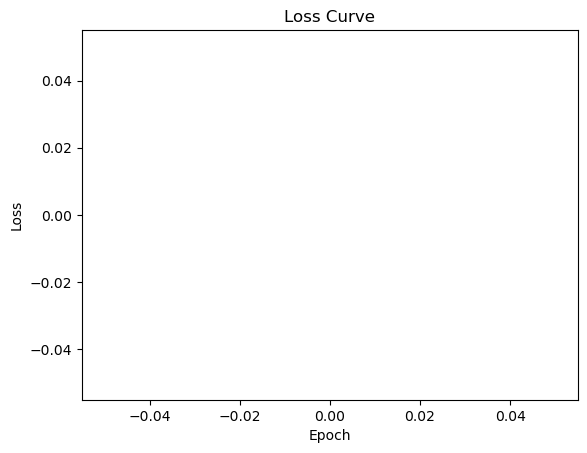

Epoch: 1, Loss: 0.7751496801175753 + 0.0im
Epoch: 2, Loss: 0.7263528497732958 + 0.0im
Epoch: 3, Loss: 0.6414988319358121 + 0.0im
Epoch: 4, Loss: 0.6148732547946679 + 0.0im
Epoch: 5, Loss: 0.5805949149348993 + 0.0im
Epoch: 6, Loss: 0.5565960049280828 + 0.0im
Epoch: 7, Loss: 0.5405354725473929 + 0.0im
Epoch: 8, Loss: 0.5231788490458996 + 0.0im
Epoch: 9, Loss: 0.491785108940353 + 0.0im
Epoch: 10, Loss: 0.4615616130477786 + 0.0im
Epoch: 11, Loss: 0.4355563115987498 + 0.0im
Epoch: 12, Loss: 0.3947870610691959 + 0.0im
Epoch: 13, Loss: 0.3640274921488637 + 0.0im
Epoch: 14, Loss: 0.341233906792406 + 0.0im
Epoch: 15, Loss: 0.31509876608525444 + 0.0im
Epoch: 16, Loss: 0.2985227055831208 + 0.0im
Epoch: 17, Loss: 0.29392131938287575 + 0.0im
Epoch: 18, Loss: 0.2916928837265368 + 0.0im
Epoch: 19, Loss: 0.28690079523735934 + 0.0im
Epoch: 20, Loss: 0.26245447539129607 + 0.0im
Epoch: 21, Loss: 0.2383394817256727 + 0.0im
Epoch: 22, Loss: 0.2268022117516987 + 0.0im
Epoch: 23, Loss: 0.20819780130214452 + 

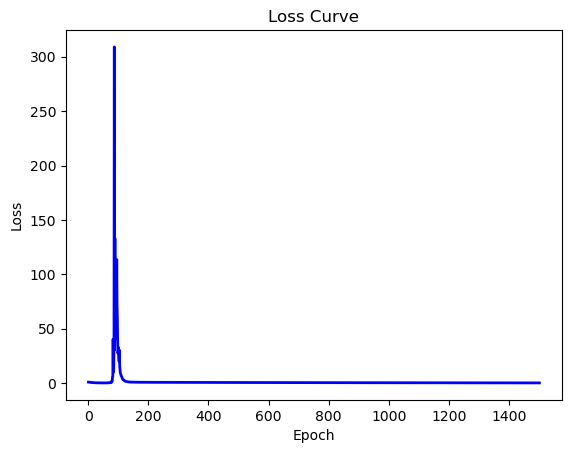

In [8]:
train(opt,layers,x,t,D,epochs=1500)


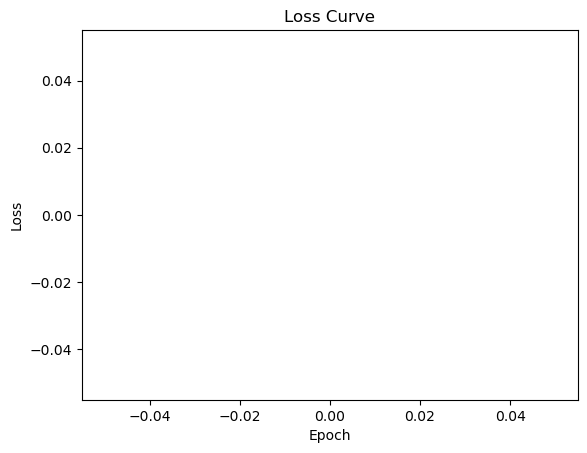

Epoch: 1, Loss: 0.05045375828737547 + 0.0im
Epoch: 2, Loss: 0.05040941503889459 + 0.0im
Epoch: 3, Loss: 0.05011810509748958 + 0.0im
Epoch: 4, Loss: 0.04984690344814519 + 0.0im
Epoch: 5, Loss: 0.04972333782624591 + 0.0im
Epoch: 6, Loss: 0.04991001248222746 + 0.0im
Epoch: 7, Loss: 0.0494672152134135 + 0.0im
Epoch: 8, Loss: 0.04928569313566208 + 0.0im
Epoch: 9, Loss: 0.04872556376383985 + 0.0im
Epoch: 10, Loss: 0.048950079185342776 + 0.0im
Epoch: 11, Loss: 0.04909229428131922 + 0.0im
Epoch: 12, Loss: 0.048918129735873686 + 0.0im
Epoch: 13, Loss: 0.04862963518025338 + 0.0im
Epoch: 14, Loss: 0.048395526278782665 + 0.0im
Epoch: 15, Loss: 0.04850908909114012 + 0.0im
Epoch: 16, Loss: 0.04776483689507884 + 0.0im
Epoch: 17, Loss: 0.047425917846471266 + 0.0im
Epoch: 18, Loss: 0.047686009556240305 + 0.0im
Epoch: 19, Loss: 0.047377268217770246 + 0.0im
Epoch: 20, Loss: 0.04772292987977621 + 0.0im
Epoch: 21, Loss: 0.04683496758550771 + 0.0im
Epoch: 22, Loss: 0.04700395532677704 + 0.0im
Epoch: 23, Los

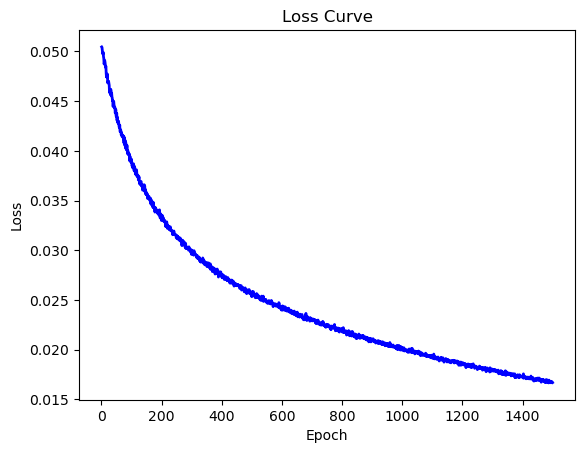

In [9]:
train(opt,layers,x,t,D,epochs=1500)

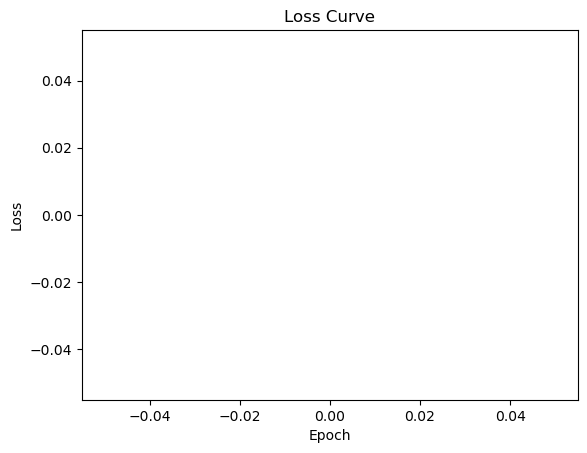

Epoch: 1, Loss: 0.01666639223655633 + 0.0im
Epoch: 2, Loss: 0.016714501468415993 + 0.0im
Epoch: 3, Loss: 0.016555205671676683 + 0.0im
Epoch: 4, Loss: 0.016695588385438002 + 0.0im
Epoch: 5, Loss: 0.016704225533718173 + 0.0im
Epoch: 6, Loss: 0.01659708095872872 + 0.0im
Epoch: 7, Loss: 0.01665780892729116 + 0.0im
Epoch: 8, Loss: 0.016778673170274257 + 0.0im
Epoch: 9, Loss: 0.016487989063451853 + 0.0im
Epoch: 10, Loss: 0.0165957327761488 + 0.0im
Epoch: 11, Loss: 0.016724938805731473 + 0.0im
Epoch: 12, Loss: 0.016562336948691133 + 0.0im
Epoch: 13, Loss: 0.016699411164546537 + 0.0im
Epoch: 14, Loss: 0.016488249938185724 + 0.0im
Epoch: 15, Loss: 0.016611097055113076 + 0.0im
Epoch: 16, Loss: 0.0166347689493469 + 0.0im
Epoch: 17, Loss: 0.01665080416228301 + 0.0im
Epoch: 18, Loss: 0.016527999988496734 + 0.0im
Epoch: 19, Loss: 0.0165750288878154 + 0.0im
Epoch: 20, Loss: 0.016586001631584392 + 0.0im
Epoch: 21, Loss: 0.016401997418634396 + 0.0im
Epoch: 22, Loss: 0.01662997387580327 + 0.0im
Epoch: 2

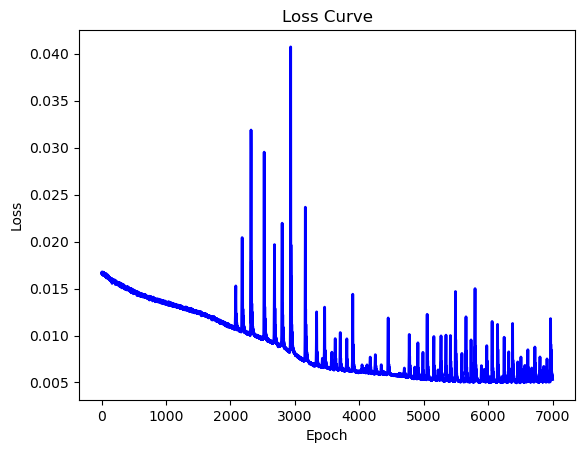

In [10]:
train(opt,layers,x,t,D,epochs=7000)

In [ ]:
opt.α=0.01

0.01

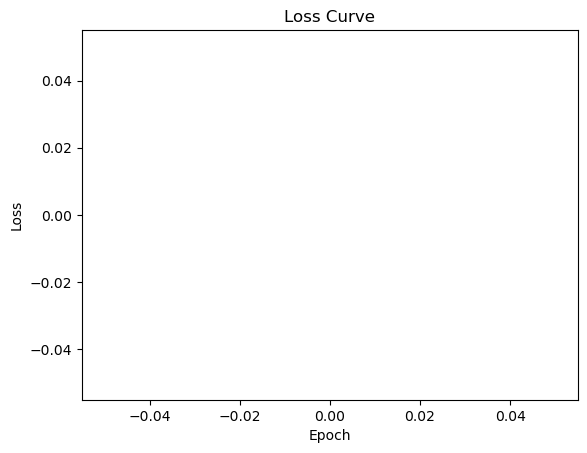

Epoch: 1, Loss: 0.005335197380972712 + 0.0im
Epoch: 2, Loss: 0.00524466858140273 + 0.0im
Epoch: 3, Loss: 0.005109192037064288 + 0.0im
Epoch: 4, Loss: 0.00506016194222098 + 0.0im
Epoch: 5, Loss: 0.005212958495604825 + 0.0im
Epoch: 6, Loss: 0.005164497317582814 + 0.0im
Epoch: 7, Loss: 0.005073892233890807 + 0.0im
Epoch: 8, Loss: 0.005066204941350562 + 0.0im
Epoch: 9, Loss: 0.005107216396026118 + 0.0im
Epoch: 10, Loss: 0.005060239707987755 + 0.0im
Epoch: 11, Loss: 0.005026389373493191 + 0.0im
Epoch: 12, Loss: 0.005050182111972939 + 0.0im
Epoch: 13, Loss: 0.005032146428315997 + 0.0im
Epoch: 14, Loss: 0.0050336400773615215 + 0.0im
Epoch: 15, Loss: 0.0050335001394581115 + 0.0im
Epoch: 16, Loss: 0.005067369654121966 + 0.0im
Epoch: 17, Loss: 0.005091638996624194 + 0.0im
Epoch: 18, Loss: 0.004917358115152129 + 0.0im
Epoch: 19, Loss: 0.005000864988844797 + 0.0im
Epoch: 20, Loss: 0.005098616380154394 + 0.0im
Epoch: 21, Loss: 0.005017629658423344 + 0.0im
Epoch: 22, Loss: 0.00495892859031055 + 0.0i

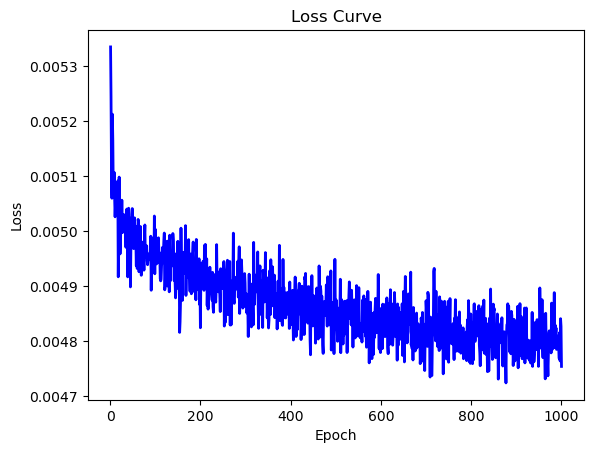

In [12]:
train(opt,layers,x,t,D,epochs=1000)